# 06 · Modelo GBTRegressor e índice de preselección territorial

Ejecución en el nodo primario de EMR con el kernel **American Tower - PySpark**. Integra ingeniería de características sobre las tablas Gold, entrenamiento y calibración de `GBTRegressor` en Spark MLlib, evaluación cronológica frente a líneas base, reentrenamiento productivo, índice de preselección territorial con pruebas de estabilidad, cartografía distrital y publicación de inferencias en Gold.


## 1. Configuración y variables de control


In [10]:
import os
import sys
import uuid
import json
import subprocess
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path, PurePosixPath

import boto3
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

# Identidad del modelo
MODEL_NAME = "gbt_regressor"
MODEL_AUTHOR = "Eddu"

# Rutas S3 y manifiesto Gold
REGION = "us-east-1"
OPERATIONS_BUCKET = "american-tower-dev-operations-1dd72256126674a5893dfca3df"
GOLD_BUCKET = "american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee"
ARTIFACTS_BUCKET = "american-tower-dev-artifacts-74d32893263161eaef72faf57a"
GOLD_RUN_URI = "s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T073334Z-7ea4f607ff/gold/_SUCCESS.json"

# Variables de control de ejecución
FORCE_REBUILD_FEATURES = False
FORCE_RETRAIN = True
RUN_TUNING_GRID = True
PUBLISH_PREDICTIONS_TO_GOLD = True
GENERATE_MAP = True

# Parámetros de suficiencia de datos y pesos del índice territorial
MIN_TESTS_SUFICIENCIA = 10
MIN_TESELAS_SUFICIENCIA = 2
TOP_K = 50
PESO_VELOCIDAD = 0.40
PESO_POBLACION = 0.35
PESO_COBERTURA_4G = 0.25

# Recursos de cómputo y rutas de salida
EXECUTORS = 2
CACHE_DIR = Path("/mnt/american-tower-cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
RUN_ID = f"{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')}-{uuid.uuid4().hex[:10]}"

FEATURES_CACHE_URI = f"s3://{OPERATIONS_BUCKET}/cache/features_{MODEL_NAME}_v2"
MODEL_S3_URI = f"s3://{ARTIFACTS_BUCKET}/models/{MODEL_NAME}"
EVAL_MODEL_S3_URI = f"s3://{ARTIFACTS_BUCKET}/models/{MODEL_NAME}_eval_2022"
PREDICTIONS_GOLD_KEY = f"predicciones_modelos/modelo_{MODEL_NAME}.parquet"
OUT_OPS_ROOT = f"s3://{OPERATIONS_BUCKET}/run_id={RUN_ID}/modelo_{MODEL_NAME}"

def show_values(values):
    display(pd.DataFrame(list(values.items()), columns=["Indicador", "Valor"]))

def show_rows(rows, columns=None):
    display(pd.DataFrame(rows, columns=columns))

show_values({
    "Modelo / Autor": f"{MODEL_NAME} ({MODEL_AUTHOR})",
    "FORCE_REBUILD_FEATURES": FORCE_REBUILD_FEATURES,
    "FORCE_RETRAIN": FORCE_RETRAIN,
    "RUN_TUNING_GRID": RUN_TUNING_GRID,
    "GENERATE_MAP": GENERATE_MAP,
    "PUBLISH_PREDICTIONS_TO_GOLD": PUBLISH_PREDICTIONS_TO_GOLD,
    "Modelo productivo S3": MODEL_S3_URI,
    "Predicciones Gold": f"s3://{GOLD_BUCKET}/{PREDICTIONS_GOLD_KEY}",
})

,Indicador,Valor
0,Modelo / Autor,gbt_regressor (Eddu)
1,FORCE_REBUILD_FEATURES,False
2,FORCE_RETRAIN,True
3,RUN_TUNING_GRID,True
4,GENERATE_MAP,True
5,PUBLISH_PREDICTIONS_TO_GOLD,True
6,Modelo productivo S3,s3://american-tower-dev-artifacts-74d328932631...
7,Predicciones Gold,s3://american-tower-dev-gold-00f4f2b4cf37bac32...


## 2. Linaje de entrada y sesión Spark


In [11]:
s3 = boto3.client("s3", region_name=REGION)

def s3_path(uri):
    if not isinstance(uri, str) or not uri.startswith("s3://"):
        raise ValueError(f"URI S3 inválida: {uri}")
    bucket, _, key = uri[5:].partition("/")
    return bucket, key

def read_json_s3(uri):
    b, k = s3_path(uri)
    return json.loads(s3.get_object(Bucket=b, Key=k)["Body"].read().decode("utf-8"))

def save_json_s3(uri, payload):
    b, k = s3_path(uri)
    s3.put_object(
        Bucket=b, Key=k,
        Body=json.dumps(payload, indent=2, ensure_ascii=False, default=str).encode("utf-8"),
        ContentType="application/json",
    )
    return uri

def s3_prefix_exists(uri):
    b, k = s3_path(uri)
    prefix = k.rstrip("/") + "/"
    resp = s3.list_objects_v2(Bucket=b, Prefix=prefix, MaxKeys=1)
    return resp.get("KeyCount", 0) > 0

def persist_figure(fig, name):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=180, bbox_inches="tight", facecolor="white")
    data = buf.getvalue()
    b, k = s3_path(f"{OUT_OPS_ROOT}/{name}")
    s3.put_object(Bucket=b, Key=k, Body=data, ContentType="image/png")
    local_copy = CACHE_DIR / name
    local_copy.write_bytes(data)
    plt.show()
    plt.close(fig)
    print(f"s3://{b}/{k}")
    return f"s3://{b}/{k}"

gold_manifest = read_json_s3(GOLD_RUN_URI)
bronze_manifest = read_json_s3(gold_manifest["bronze_manifest_uri"])

SPARK_HOME = Path("/usr/lib/spark")
if SPARK_HOME.is_dir():
    os.environ["SPARK_HOME"] = str(SPARK_HOME)
    os.environ["PYSPARK_PYTHON"] = sys.executable
    os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
    py4j_zips = sorted((SPARK_HOME / "python" / "lib").glob("py4j-*.zip"))
    if py4j_zips:
        sys.path.insert(0, str(py4j_zips[0]))
    sys.path.insert(0, str(SPARK_HOME / "python"))

from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import SQLTransformer, StringIndexer, VectorAssembler
from pyspark.ml.regression import GBTRegressor, LinearRegression

events_uri = f"s3://{OPERATIONS_BUCKET}/run_id={RUN_ID}/eventos_spark/"
s3.put_object(Bucket=OPERATIONS_BUCKET, Key=f"run_id={RUN_ID}/eventos_spark/", Body=b"")

spark = (
    SparkSession.builder.master("yarn")
    .appName(f"american-tower-{MODEL_NAME}")
    .config("spark.submit.deployMode", "client")
    .config("spark.executor.instances", str(EXECUTORS))
    .config("spark.executor.cores", "4")
    .config("spark.executor.memory", "8g")
    .config("spark.executor.memoryOverhead", "3g")
    .config("spark.sql.shuffle.partitions", "48")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.eventLog.enabled", "true")
    .config("spark.eventLog.dir", events_uri)
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

show_values({
    "Aplicación Spark": spark.sparkContext.applicationId,
    "Versión Spark": spark.version,
    "Panel Gold": gold_manifest["panel_uri"],
    "Contexto Gold": gold_manifest["context_uri"],
    "Eventos Spark": events_uri,
})

/opt/american-tower/venv/lib64/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
26/11/27 16:49:34 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


,Indicador,Valor
0,Aplicación Spark,application_1795793929266_0002
1,Versión Spark,3.5.0-amzn-1
2,Panel Gold,s3://american-tower-dev-gold-00f4f2b4cf37bac32...
3,Contexto Gold,s3://american-tower-dev-gold-00f4f2b4cf37bac32...
4,Eventos Spark,s3://american-tower-dev-operations-1dd72256126...


## 3. Ingeniería de características

Construcción del conjunto de atributos a nivel distrito-trimestre a partir de `panel_distrital` y `contexto_territorial`: rezagos logarítmicos, volatilidad móvil, razón frente a la mediana departamental, volumen de pruebas, densidad demográfica y cobertura 4G con imputación departamental para registros sin declaración OSIPTEL.


In [12]:
FEATURE_NUMERIC_COLS = [
    "log_vel_t",
    "log_vel_lag1",
    "log_vel_lag2",
    "log_vel_lag4",
    "log_vel_media_4t",
    "vel_std_4t",
    "log_vel_delta_1t",
    "vel_ratio_media_4t",
    "vel_ratio_depto_t",
    "log_tests_t",
    "teselas_observadas_t",
    "quarter",
    "log_poblacion_2020",
    "superficie_km2",
    "log_densidad_hab_km2",
    "pct_cobertura_4g_imputada",
    "en_punto_ciego_osiptel",
]

def build_feature_table(spark, panel_uri, context_uri):
    panel = spark.read.parquet(panel_uri)
    context_raw = spark.read.parquet(context_uri).select(
        "ubigeo",
        "departamento",
        "poblacion_2020",
        "centros_en_reporte",
        "centros_con_dato_4g",
        "centros_con_4g_declarada",
    ).withColumn(
        "pct_cobertura_4g_raw",
        F.when(
            F.col("centros_con_dato_4g") > 0,
            100.0 * F.col("centros_con_4g_declarada") / F.col("centros_con_dato_4g"),
        ),
    )

    dept_cov_med = (
        context_raw.filter(F.col("pct_cobertura_4g_raw").isNotNull())
        .groupBy("departamento")
        .agg(F.percentile_approx("pct_cobertura_4g_raw", 0.5).alias("dept_cov_4g_med"))
    )
    nat_cov_med = (
        context_raw.filter(F.col("pct_cobertura_4g_raw").isNotNull())
        .agg(F.percentile_approx("pct_cobertura_4g_raw", 0.5).alias("m"))
        .first()
        .m
    )

    context = (
        context_raw.join(dept_cov_med, "departamento", "left")
        .withColumn(
            "pct_cobertura_4g_imputada",
            F.coalesce(F.col("pct_cobertura_4g_raw"), F.col("dept_cov_4g_med"), F.lit(float(nat_cov_med))),
        )
        .withColumn("en_punto_ciego_osiptel", F.when(F.col("centros_en_reporte").isNull(), F.lit(1.0)).otherwise(F.lit(0.0)))
        .drop("departamento")
    )

    dept_med = (
        panel.filter("observado")
        .groupBy("departamento", "period_id")
        .agg(F.percentile_approx("vel_descarga_mbps", 0.5).alias("vel_mediana_depto_t"))
    )

    w_dist = Window.partitionBy("ubigeo").orderBy("period_id")
    w_roll4 = w_dist.rowsBetween(-3, 0)

    return (
        panel.join(context, "ubigeo", "left")
        .join(dept_med, ["departamento", "period_id"], "left")
        .withColumn("vel_t", F.col("vel_descarga_mbps"))
        .withColumn("vel_lag1", F.coalesce(F.lag("vel_descarga_mbps", 1).over(w_dist), F.col("vel_t")))
        .withColumn("vel_lag2", F.coalesce(F.lag("vel_descarga_mbps", 2).over(w_dist), F.col("vel_lag1")))
        .withColumn("vel_media_4t", F.coalesce(F.avg("vel_descarga_mbps").over(w_roll4), F.col("vel_t")))
        .withColumn("vel_lag4", F.coalesce(F.lag("vel_descarga_mbps", 4).over(w_dist), F.col("vel_media_4t")))
        .withColumn("vel_std_4t", F.coalesce(F.stddev("vel_descarga_mbps").over(w_roll4), F.lit(0.0)))
        .withColumn("vel_mediana_depto_t", F.coalesce(F.col("vel_mediana_depto_t"), F.col("vel_t")))
        .withColumn("log_vel_t", F.log1p(F.greatest(F.col("vel_t"), F.lit(0.0))))
        .withColumn("log_vel_lag1", F.log1p(F.greatest(F.col("vel_lag1"), F.lit(0.0))))
        .withColumn("log_vel_lag2", F.log1p(F.greatest(F.col("vel_lag2"), F.lit(0.0))))
        .withColumn("log_vel_lag4", F.log1p(F.greatest(F.col("vel_lag4"), F.lit(0.0))))
        .withColumn("log_vel_media_4t", F.log1p(F.greatest(F.col("vel_media_4t"), F.lit(0.0))))
        .withColumn("log_vel_delta_1t", F.col("log_vel_t") - F.col("log_vel_lag1"))
        .withColumn("vel_ratio_media_4t", F.col("vel_t") / F.greatest(F.col("vel_media_4t"), F.lit(0.5)))
        .withColumn("vel_ratio_depto_t", F.col("vel_t") / F.greatest(F.col("vel_mediana_depto_t"), F.lit(0.5)))
        .withColumn("log_tests_t", F.log1p(F.coalesce(F.col("tests"), F.lit(0)).cast("double")))
        .withColumn("teselas_observadas_t", F.coalesce(F.col("teselas_observadas"), F.lit(0)).cast("double"))
        .withColumn("sample_weight", F.greatest(F.col("log_tests_t"), F.lit(0.5)))
        .withColumn("log_poblacion_2020", F.log1p(F.coalesce(F.col("poblacion_2020"), F.lit(0.0))))
        .withColumn(
            "log_densidad_hab_km2",
            F.log1p(
                F.when(F.col("superficie_km2") > 0, F.coalesce(F.col("poblacion_2020"), F.lit(0.0)) / F.col("superficie_km2"))
                .otherwise(F.lit(0.0))
            ),
        )
        .withColumn("objetivo", F.lead("vel_descarga_mbps", 1).over(w_dist))
        .withColumn("objetivo_log_delta", F.log1p(F.greatest(F.col("objetivo"), F.lit(0.0))) - F.col("log_vel_t"))
        .withColumn("period_id_objetivo", F.col("period_id") + F.lit(1))
        .withColumn("year_objetivo", F.floor((F.col("period_id") + F.lit(1)) / 4).cast("int"))
        .withColumn("quarter_objetivo", (((F.col("period_id") + F.lit(1)) % 4) + 1).cast("int"))
    )

if not FORCE_REBUILD_FEATURES and s3_prefix_exists(FEATURES_CACHE_URI):
    features_full = spark.read.parquet(FEATURES_CACHE_URI).cache()
else:
    features_full = build_feature_table(spark, gold_manifest["panel_uri"], gold_manifest["context_uri"])
    features_full.write.mode("overwrite").option("compression", "snappy").parquet(FEATURES_CACHE_URI)
    features_full = spark.read.parquet(FEATURES_CACHE_URI).cache()

all_observed_pairs = features_full.filter(F.col("vel_t").isNotNull() & F.col("objetivo").isNotNull()).cache()

pairs = (
    all_observed_pairs.filter(F.col("year_objetivo").between(2020, 2024))
    .withColumn(
        "particion",
        F.when(F.col("year_objetivo") <= 2022, F.lit("entrenamiento"))
        .when(F.col("year_objetivo") == 2023, F.lit("validacion"))
        .otherwise(F.lit("prueba")),
    )
    .cache()
)

display(
    all_observed_pairs.groupBy("year_objetivo")
    .agg(F.count("*").alias("pares"), F.count_distinct("ubigeo").alias("distritos"))
    .orderBy("year_objetivo")
    .toPandas()
)

26/11/27 16:49:35 WARN CacheManager: Asked to cache already cached data.
26/11/27 16:49:35 WARN CacheManager: Asked to cache already cached data.


,year_objetivo,pares,distritos
0,2019,2626,1075
1,2020,4185,1392
2,2021,5126,1547
3,2022,5344,1574
4,2023,5248,1547
5,2024,5666,1645
6,2025,5912,1662
7,2026,1450,1450


## 4. Entrenamiento, calibración y modelo productivo

Fase de evaluación cronológica sobre `2020–2022` (validación en `2023`, prueba en `2024`) con estimador de corrección de Duan integrado en el `PipelineModel` para la transformación inversa desde escala logarítmica a Mbps. Seleccionados los hiperparámetros óptimos, se ajusta el modelo productivo sobre el histórico completo de pares observados hasta `2026-T1` y se persiste en S3 Artifacts.


In [13]:
train_df = pairs.filter("particion = 'entrenamiento'").cache()
val_df = pairs.filter("particion = 'validacion'").cache()
test_df = pairs.filter("particion = 'prueba'").cache()

def regression_metrics(frame, pred_col):
    row = frame.select(
        F.count("*").alias("n"),
        F.avg(F.abs(F.col(pred_col) - F.col("objetivo"))).alias("mae_mbps"),
        F.sqrt(F.avg(F.pow(F.col(pred_col) - F.col("objetivo"), 2))).alias("rmse_mbps"),
        F.avg(F.col(pred_col) - F.col("objetivo")).alias("sesgo_mbps"),
        F.avg(F.pow(F.col(pred_col) - F.col("objetivo"), 2)).alias("mse"),
        F.var_pop("objetivo").alias("variance"),
    ).first()
    r2 = 1.0 - (row.mse / row.variance) if row.variance else None
    return {
        "n": int(row.n),
        "mae_mbps": round(float(row.mae_mbps), 3),
        "rmse_mbps": round(float(row.rmse_mbps), 3),
        "sesgo_mbps": round(float(row.sesgo_mbps), 3),
        "r2": round(float(r2), 4) if r2 is not None else None,
    }

def fit_calibrated_gbt(fit_frame, max_depth=3, max_iter=40, step_size=0.08, subsampling_rate=0.8):
    dept_indexer = StringIndexer(
        inputCol="departamento", outputCol="departamento_idx", handleInvalid="keep"
    )
    assembler = VectorAssembler(
        inputCols=FEATURE_NUMERIC_COLS + ["departamento_idx"],
        outputCol="features",
        handleInvalid="keep",
    )
    gbt = GBTRegressor(
        featuresCol="features",
        labelCol="objetivo_log_delta",
        weightCol="sample_weight",
        predictionCol="raw_log_delta_pred",
        maxDepth=max_depth,
        maxIter=max_iter,
        stepSize=step_size,
        subsamplingRate=subsampling_rate,
        maxBins=64,
        seed=42,
    )
    base_model = Pipeline(stages=[dept_indexer, assembler, gbt]).fit(fit_frame)

    # Estimador de Duan sobre los residuos logarítmicos del propio conjunto de entrenamiento
    # Recortamos residuos extremos [-1.5, 1.5] para evitar inflación por outliers aislados
    resid_df = base_model.transform(fit_frame).select(
        F.greatest(F.least(F.col("objetivo_log_delta") - F.col("raw_log_delta_pred"), F.lit(1.5)), F.lit(-1.5)).alias("r"),
        "sample_weight",
    )
    duan_row = resid_df.agg(
        (F.sum(F.exp("r") * F.col("sample_weight")) / F.sum("sample_weight")).alias("smearing")
    ).first()
    smearing = float(duan_row.smearing)

    to_mbps = SQLTransformer(
        statement=(
            f"SELECT *, GREATEST(0.0, (EXP(log_vel_t + raw_log_delta_pred) * {smearing:.8f}) - 1.0) "
            "AS prediction FROM __THIS__"
        )
    )
    return PipelineModel(stages=list(base_model.stages) + [to_mbps]), smearing

tuning_rows = []
if not FORCE_RETRAIN and s3_prefix_exists(MODEL_S3_URI) and s3_prefix_exists(EVAL_MODEL_S3_URI):
    eval_model = PipelineModel.load(EVAL_MODEL_S3_URI)
    prod_model = PipelineModel.load(MODEL_S3_URI)
    best_params = {"origen": "cargado_desde_s3"}
    eval_smearing = None
    prod_smearing = None
else:
    if RUN_TUNING_GRID:
        grid = [
            {"max_depth": 3, "max_iter": 40, "step_size": 0.08, "subsampling_rate": 0.8},
            {"max_depth": 4, "max_iter": 50, "step_size": 0.06, "subsampling_rate": 0.8},
            {"max_depth": 4, "max_iter": 80, "step_size": 0.04, "subsampling_rate": 0.8},
            {"max_depth": 5, "max_iter": 50, "step_size": 0.05, "subsampling_rate": 0.8},
        ]
    else:
        grid = [{"max_depth": 3, "max_iter": 40, "step_size": 0.08, "subsampling_rate": 0.8}]

    eval_model = None
    best_mae = float("inf")
    best_params = None
    eval_smearing = None

    for cfg in grid:
        candidate, sm = fit_calibrated_gbt(train_df, **cfg)
        m = regression_metrics(candidate.transform(val_df), "prediction")
        tuning_rows.append({**cfg, "duan_smearing": round(sm, 4), **m})
        if m["mae_mbps"] < best_mae:
            best_mae = m["mae_mbps"]
            eval_model = candidate
            best_params = cfg
            eval_smearing = sm

    # Reentrenamiento productivo sobre el histórico completo de pares observados (2019-T1 a 2026-T1)
    prod_model, prod_smearing = fit_calibrated_gbt(all_observed_pairs, **best_params)

    eval_model.write().overwrite().save(EVAL_MODEL_S3_URI)
    prod_model.write().overwrite().save(MODEL_S3_URI)
    display(pd.DataFrame(tuning_rows).sort_values("mae_mbps"))

show_values({
    "Modelo": MODEL_NAME,
    "Hiperparámetros óptimos": json.dumps(best_params),
    "Factor Duan evaluación (2020–2022)": round(eval_smearing, 4) if eval_smearing else "cargado",
    "Factor Duan productivo (histórico completo)": round(prod_smearing, 4) if prod_smearing else "cargado",
    "Pares modelo productivo": all_observed_pairs.count(),
    "Artefacto productivo S3": MODEL_S3_URI,
})

26/11/27 16:49:36 WARN CacheManager: Asked to cache already cached data.
26/11/27 16:49:36 WARN CacheManager: Asked to cache already cached data.
26/11/27 16:49:36 WARN CacheManager: Asked to cache already cached data.


,max_depth,max_iter,step_size,subsampling_rate,duan_smearing,n,mae_mbps,rmse_mbps,sesgo_mbps,r2
0,3,40,0.08,0.8,1.1448,5248,11.435,18.644,-2.313,0.0724
3,5,50,0.05,0.8,1.1281,5248,11.498,18.853,-2.716,0.0515
2,4,80,0.04,0.8,1.1362,5248,11.504,18.819,-2.518,0.0550
1,4,50,0.06,0.8,1.1360,5248,11.525,18.851,-2.635,0.0518


,Indicador,Valor
0,Modelo,gbt_regressor
1,Hiperparámetros óptimos,"{""max_depth"": 3, ""max_iter"": 40, ""step_size"": ..."
2,Factor Duan evaluación (2020–2022),1.1448
3,Factor Duan productivo (histórico completo),1.1326
4,Pares modelo productivo,35557
5,Artefacto productivo S3,s3://american-tower-dev-artifacts-74d328932631...


## 5. Evaluación comparativa y diagnóstico de errores

Comparación cronológica del modelo de evaluación (`2020–2022`) frente a persistencia y regresión lineal simple sobre validación (`2023`) y prueba (`2024`), desagregada por universo completo y distritos con suficiencia de datos (`tests >= 10`, `teselas_observadas >= 2`).


26/11/27 16:51:04 WARN Instrumentation: [a8a9188a] regParam is zero, which might cause numerical instability and overfitting.


,particion,segmento,year_objetivo,modelo,n,mae_mbps,rmse_mbps,sesgo_mbps,r2
0,validacion,Todos los pares,2023,Persistencia,5248,13.279,21.722,-1.245,-0.2590
1,validacion,Todos los pares,2023,Regresión lineal simple,5248,11.680,19.130,-5.309,0.0235
2,validacion,Todos los pares,2023,GBTRegressor (Eddu),5248,11.435,18.644,-2.313,0.0724
3,validacion,Con suficiencia (tests>=10),2023,Persistencia,3316,10.062,15.652,-1.107,-0.0632
4,validacion,Con suficiencia (tests>=10),2023,Regresión lineal simple,3316,9.538,14.782,-5.154,0.0517
5,validacion,Con suficiencia (tests>=10),2023,GBTRegressor (Eddu),3316,9.313,14.004,-0.107,0.1490
6,prueba,Todos los pares,2024,Persistencia,5666,14.648,23.644,-1.487,-0.4802
7,prueba,Todos los pares,2024,Regresión lineal simple,5666,13.091,20.289,-7.884,-0.0899
8,prueba,Todos los pares,2024,GBTRegressor (Eddu),5666,11.941,19.165,-2.626,0.0275
9,prueba,Con suficiencia (tests>=10),2024,Persistencia,3990,11.436,16.726,-1.942,-0.1737


,departamento,pares,mae_persistencia,mae_lr_base,mae_gbt,sesgo_gbt
0,LIMA,344,7.829,13.036,7.738,1.793
1,CUSCO,335,11.749,12.041,10.363,-3.632
2,CAJAMARCA,297,14.534,11.844,11.807,-2.528
3,PUNO,276,12.191,11.237,10.764,0.200
4,JUNIN,253,11.225,10.816,10.310,-2.730
5,AREQUIPA,238,10.552,11.356,9.026,0.426
6,LA LIBERTAD,222,11.433,10.018,8.837,-0.127
7,ANCASH,206,11.317,10.920,9.481,-1.399
8,PIURA,202,11.049,11.478,10.598,0.170
9,AYACUCHO,192,11.544,10.514,9.809,-0.680


,feature,importance
8,vel_ratio_depto_t,0.474993
7,vel_ratio_media_4t,0.140875
17,departamento_idx,0.102050
9,log_tests_t,0.086865
10,teselas_observadas_t,0.042594
15,pct_cobertura_4g_imputada,0.027700
3,log_vel_lag4,0.023575
1,log_vel_lag1,0.023559
6,log_vel_delta_1t,0.017383
5,vel_std_4t,0.014247


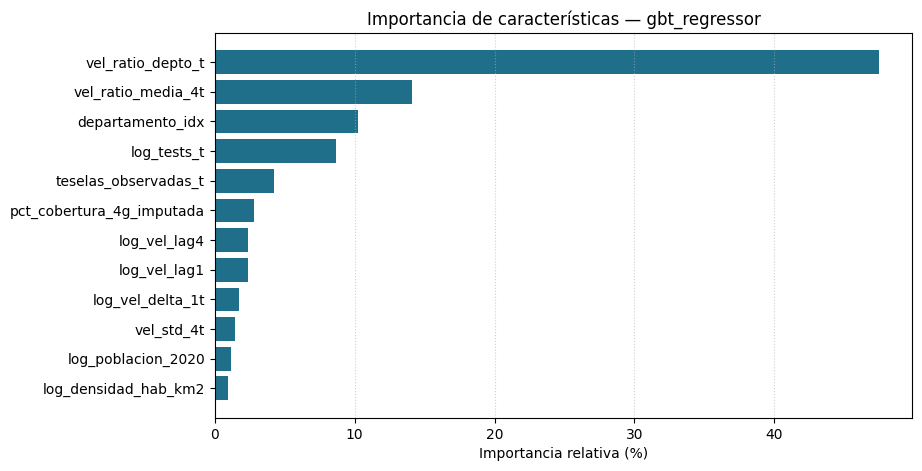

s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261127T164934Z-e45684e39d/modelo_gbt_regressor/importancia_gbt_regressor.png


In [14]:
base_assembler = VectorAssembler(inputCols=["vel_t"], outputCol="base_features")
base_lr = LinearRegression(featuresCol="base_features", labelCol="objetivo", predictionCol="pred_lr_base")
base_lr_model = Pipeline(stages=[base_assembler, base_lr]).fit(train_df)

comparison = []
suf_filter = (F.col("tests") >= MIN_TESTS_SUFICIENCIA) & (F.col("teselas_observadas") >= MIN_TESELAS_SUFICIENCIA)

for part_name, year_lbl, frame in [("validacion", 2023, val_df), ("prueba", 2024, test_df)]:
    scored = eval_model.transform(base_lr_model.transform(frame)).cache()
    for segmento, sub in [("Todos los pares", scored), (f"Con suficiencia (tests>={MIN_TESTS_SUFICIENCIA})", scored.filter(suf_filter))]:
        for label, col_name in [
            ("Persistencia", "vel_t"),
            ("Regresión lineal simple", "pred_lr_base"),
            (f"GBTRegressor ({MODEL_AUTHOR})", "prediction"),
        ]:
            m = regression_metrics(sub, col_name)
            comparison.append({"particion": part_name, "segmento": segmento, "year_objetivo": year_lbl, "modelo": label, **m})
    if part_name == "prueba":
        test_scored = scored
    else:
        scored.unpersist()

display(pd.DataFrame(comparison))

dept_diag = (
    test_scored.filter(suf_filter)
    .groupBy("departamento")
    .agg(
        F.count("*").alias("pares"),
        F.round(F.avg(F.abs(F.col("vel_t") - F.col("objetivo"))), 3).alias("mae_persistencia"),
        F.round(F.avg(F.abs(F.col("pred_lr_base") - F.col("objetivo"))), 3).alias("mae_lr_base"),
        F.round(F.avg(F.abs(F.col("prediction") - F.col("objetivo"))), 3).alias("mae_gbt"),
        F.round(F.avg(F.col("prediction") - F.col("objetivo")), 3).alias("sesgo_gbt"),
    )
    .orderBy(F.desc("pares"))
    .toPandas()
)
display(dept_diag)

gbt_stage = prod_model.stages[2]
feature_names = FEATURE_NUMERIC_COLS + ["departamento_idx"]
imp_df = pd.DataFrame({
    "feature": feature_names,
    "importance": gbt_stage.featureImportances.toArray(),
}).sort_values("importance", ascending=False)
display(imp_df.head(12))

fig, ax = plt.subplots(figsize=(9, 5))
top_imp = imp_df.head(12).iloc[::-1]
ax.barh(top_imp["feature"], top_imp["importance"] * 100.0, color="#1f6f8b")
ax.set_xlabel("Importancia relativa (%)")
ax.set_title(f"Importancia de características — {MODEL_NAME}")
ax.grid(axis="x", linestyle=":", alpha=0.6)
chart_imp_uri = persist_figure(fig, f"importancia_{MODEL_NAME}.png")

## 6. Índice de preselección territorial y suficiencia de datos

Clasificación de los 1,890 distritos del último trimestre observado con el modelo productivo calibrado, aplicando umbrales mínimos de suficiencia de pruebas y ponderación compuesta de velocidad proyectada, demanda poblacional y brecha de cobertura 4G.


In [15]:
def compute_priority_index(scored_quarter_pdf, w_vel=PESO_VELOCIDAD, w_pop=PESO_POBLACION, w_cov=PESO_COBERTURA_4G):
    df = scored_quarter_pdf.copy()
    df["suficiencia"] = np.where(
        ~df["observado"].fillna(False),
        "Punto ciego sin telemetria",
        np.where(
            (df["tests"].fillna(0) >= MIN_TESTS_SUFICIENCIA)
            & (df["teselas_observadas"].fillna(0) >= MIN_TESELAS_SUFICIENCIA),
            "Apto con suficiencia",
            "Baja suficiencia",
        ),
    )
    aptos = df["suficiencia"] == "Apto con suficiencia"
    df["score_vel"] = np.nan
    df["score_pop"] = df["log_poblacion_2020"].rank(pct=True)
    df["score_cov"] = 1.0 - (df["pct_cobertura_4g_imputada"].clip(0, 100) / 100.0)
    df.loc[aptos, "score_vel"] = 1.0 - df.loc[aptos, "pred_descarga_mbps"].rank(pct=True)

    df["indice_prioridad"] = np.where(
        aptos,
        100.0 * (w_vel * df["score_vel"] + w_pop * df["score_pop"] + w_cov * df["score_cov"]),
        np.nan,
    )
    df["ranking_prioridad"] = df["indice_prioridad"].rank(ascending=False, method="min")
    return df

all_periods = sorted([r.period_id for r in features_full.select("period_id").distinct().collect()])
p_prev, p_curr = all_periods[-2], all_periods[-1]
lbl_prev = f"{p_prev // 4}-T{p_prev % 4 + 1}"
lbl_curr = f"{p_curr // 4}-T{p_curr % 4 + 1}"
lbl_target = f"{(p_curr + 1) // 4}-T{(p_curr + 1) % 4 + 1}"

def score_quarter(pid, model):
    q_df = features_full.filter(F.col("period_id") == pid)
    obs_df = q_df.filter("vel_t IS NOT NULL")
    unobs_df = q_df.filter("vel_t IS NULL").withColumn("prediction", F.lit(None).cast("double"))
    cols = [
        "ubigeo", "departamento", "provincia", "distrito", "year", "quarter", "period_id",
        "year_objetivo", "quarter_objetivo", "observado", "vel_t", "tests", "teselas_observadas",
        "poblacion_2020", "log_poblacion_2020", "pct_cobertura_4g_raw", "pct_cobertura_4g_imputada",
        "en_punto_ciego_osiptel", F.col("prediction").alias("pred_descarga_mbps"),
    ]
    return model.transform(obs_df).select(*cols).unionByName(unobs_df.select(*cols)).toPandas()

pdf_prev = compute_priority_index(score_quarter(p_prev, prod_model))
pdf_curr = compute_priority_index(score_quarter(p_curr, prod_model))

obs_curr = pdf_curr[pdf_curr["pred_descarga_mbps"].notna()]
show_values({
    "Trimestre base": lbl_curr,
    "Trimestre pronosticado": lbl_target,
    "Velocidad origen promedio (Mbps)": round(float(obs_curr["vel_t"].mean()), 2),
    "Velocidad predicha promedio (Mbps)": round(float(obs_curr["pred_descarga_mbps"].mean()), 2),
    "Delta promedio (Mbps)": round(float((obs_curr["pred_descarga_mbps"] - obs_curr["vel_t"]).mean()), 2),
})

display(pdf_curr["suficiencia"].value_counts().rename_axis("categoria").reset_index(name="distritos"))

top_distritos = (
    pdf_curr[pdf_curr["suficiencia"] == "Apto con suficiencia"]
    .sort_values("indice_prioridad", ascending=False)
    .head(TOP_K)
)
display(top_distritos[[
    "ranking_prioridad", "ubigeo", "departamento", "provincia", "distrito",
    "vel_t", "pred_descarga_mbps", "tests", "poblacion_2020", "pct_cobertura_4g_imputada", "indice_prioridad"
]].head(20))

bandeja_ciegos = (
    pdf_curr[pdf_curr["suficiencia"] == "Punto ciego sin telemetria"]
    .sort_values("poblacion_2020", ascending=False)
    .head(15)
)
display(bandeja_ciegos[["ubigeo", "departamento", "provincia", "distrito", "poblacion_2020", "pct_cobertura_4g_raw", "en_punto_ciego_osiptel"]])

,Indicador,Valor
0,Trimestre base,2026-T1
1,Trimestre pronosticado,2026-T2
2,Velocidad origen promedio (Mbps),46.43
3,Velocidad predicha promedio (Mbps),48.42
4,Delta promedio (Mbps),1.99


,categoria,distritos
0,Apto con suficiencia,1019
1,Baja suficiencia,545
2,Punto ciego sin telemetria,326


,ranking_prioridad,ubigeo,departamento,provincia,distrito,vel_t,pred_descarga_mbps,tests,poblacion_2020,pct_cobertura_4g_imputada,indice_prioridad
344,1.0,160404,LORETO,MARISCAL RAMON CASTILLA,SAN PABLO,14.965923,19.198723,26.0,16897.557396,0.000000,93.419275
529,2.0,160403,LORETO,MARISCAL RAMON CASTILLA,YAVARI,30.834896,27.379226,77.0,20381.486882,0.000000,93.213481
1221,3.0,160402,LORETO,MARISCAL RAMON CASTILLA,PEBAS,31.127129,27.355519,31.0,19632.801376,0.000000,93.160142
1220,4.0,160305,LORETO,LORETO,URARINAS,25.208933,21.858245,15.0,16489.540749,0.000000,93.040036
888,5.0,160701,LORETO,DATEM DEL MARAÑON,BARRANCA,32.613792,28.414783,24.0,19416.728133,0.000000,92.947570
887,6.0,160601,LORETO,UCAYALI,CONTAMANA,16.356784,23.883115,125.0,30682.407224,11.111111,92.897103
1256,7.0,220708,SAN MARTIN,PICOTA,SHAMBOYACU,4.803182,29.573905,11.0,19030.413302,0.000000,92.469087
150,8.0,160112,LORETO,MAYNAS,BELEN,39.166918,38.282586,195.0,43228.744058,0.000000,92.220641
848,9.0,120303,JUNIN,CHANCHAMAYO,PICHANAQUI,23.422833,37.073379,288.0,93373.957888,9.523810,91.868512
151,10.0,160113,LORETO,MAYNAS,SAN JUAN BAUTISTA,32.012434,40.663826,756.0,110966.740381,0.000000,91.758714


,ubigeo,departamento,provincia,distrito,poblacion_2020,pct_cobertura_4g_raw,en_punto_ciego_osiptel
1721,160704,LORETO,DATEM DEL MARAÑON,MORONA,35483.136115,NaN,1.0
1860,190110,PASCO,PASCO,TICLACAYAN,25785.350276,56.000000,0.0
1859,160102,LORETO,MAYNAS,ALTO NANAY,25390.986222,0.000000,0.0
1792,160202,LORETO,ALTO AMAZONAS,BALSAPUERTO,20771.839562,0.000000,0.0
1652,160605,LORETO,UCAYALI,SARAYACU,17010.036644,37.500000,0.0
1711,140202,LAMBAYEQUE,FERREÑAFE,CAÑARIS,15075.672089,0.000000,0.0
1886,160604,LORETO,UCAYALI,PAMPA HERMOSA,14287.842310,NaN,1.0
1795,160706,LORETO,DATEM DEL MARAÑON,ANDOAS,14111.247940,0.000000,0.0
1889,250103,UCAYALI,CORONEL PORTILLO,IPARIA,12466.042591,0.000000,0.0
1885,160303,LORETO,LORETO,TIGRE,10718.645636,0.000000,0.0


## 7. Estabilidad de la priorización

Verificación de consistencia del ranking mediante coincidencia en Top-K, índice de Jaccard y correlación de Spearman entre trimestres consecutivos y bajo perturbaciones de pesos.


In [16]:
def stability_metrics(df_a, df_b, k=TOP_K):
    a_apt = df_a[df_a["suficiencia"] == "Apto con suficiencia"].dropna(subset=["indice_prioridad"])
    b_apt = df_b[df_b["suficiencia"] == "Apto con suficiencia"].dropna(subset=["indice_prioridad"])
    top_a = set(a_apt.sort_values("indice_prioridad", ascending=False).head(k)["ubigeo"])
    top_b = set(b_apt.sort_values("indice_prioridad", ascending=False).head(k)["ubigeo"])
    overlap = len(top_a & top_b)
    jaccard = overlap / len(top_a | top_b) if (top_a | top_b) else 0.0
    common = a_apt[["ubigeo", "indice_prioridad"]].merge(
        b_apt[["ubigeo", "indice_prioridad"]], on="ubigeo", suffixes=("_a", "_b")
    )
    spearman = common["indice_prioridad_a"].corr(common["indice_prioridad_b"], method="spearman")
    return {
        "top_k": k,
        "coincidencias": overlap,
        "overlap_pct": round(100.0 * overlap / k, 2),
        "jaccard": round(jaccard, 4),
        "spearman_global": round(float(spearman), 4),
        "distritos_comunes": len(common),
    }

stab_rows = [
    {"prueba": f"Temporal {lbl_prev} vs {lbl_curr} · Top 50", **stability_metrics(pdf_prev, pdf_curr, k=50)},
    {"prueba": f"Temporal {lbl_prev} vs {lbl_curr} · Top 100", **stability_metrics(pdf_prev, pdf_curr, k=100)},
]

for name, (wv, wp, wc) in [
    ("Sensibilidad · Mayor peso Velocidad 50/30/20", (0.50, 0.30, 0.20)),
    ("Sensibilidad · Mayor peso Población 30/45/25", (0.30, 0.45, 0.25)),
    ("Sensibilidad · Mayor peso Cobertura 4G 30/30/40", (0.30, 0.30, 0.40)),
]:
    alt = compute_priority_index(pdf_curr, w_vel=wv, w_pop=wp, w_cov=wc)
    stab_rows.append({"prueba": name, **stability_metrics(pdf_curr, alt, k=TOP_K)})

display(pd.DataFrame(stab_rows))

,prueba,top_k,coincidencias,overlap_pct,jaccard,spearman_global,distritos_comunes
0,Temporal 2025-T4 vs 2026-T1 · Top 50,50,36,72.0,0.5625,0.8389,866
1,Temporal 2025-T4 vs 2026-T1 · Top 100,100,65,65.0,0.4815,0.8389,866
2,Sensibilidad · Mayor peso Velocidad 50/30/20,50,47,94.0,0.8868,0.9852,1019
3,Sensibilidad · Mayor peso Población 30/45/25,50,43,86.0,0.7544,0.9657,1019
4,Sensibilidad · Mayor peso Cobertura 4G 30/30/40,50,43,86.0,0.7544,0.9510,1019


## 8. Mapa distrital de priorización

Distribución geográfica de los 1,890 distritos del Perú según el índice de preselección territorial, destacando los Top 50 distritos prioritarios y etiquetando los diez primeros.


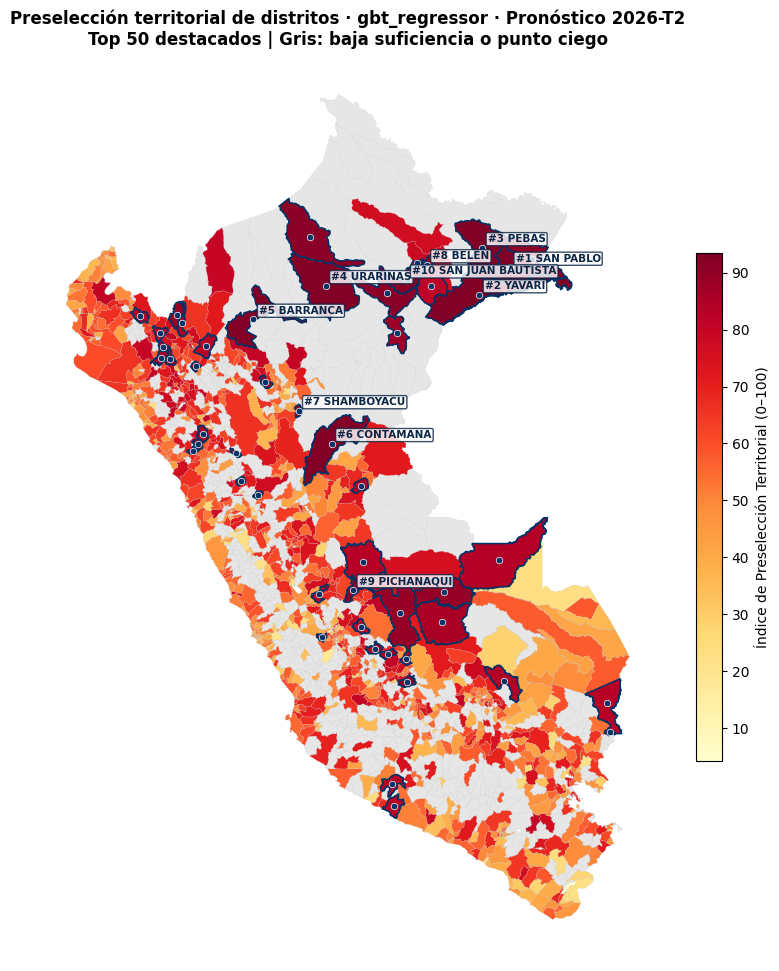

s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261127T164934Z-e45684e39d/modelo_gbt_regressor/mapa_priorizacion_gbt_regressor.png


In [17]:
chart_map_uri = None
if GENERATE_MAP:
    import geopandas as gpd

    cached_gpkg = CACHE_DIR / "DISTRITO.gpkg"
    if not cached_gpkg.exists():
        district_items = [
            it for it in bronze_manifest["objects"]
            if it["source"] == "inei" and PurePosixPath(it["key"]).name.lower() == "distrito.rar"
        ]
        rar_path = CACHE_DIR / "Distrito.rar"
        s3.download_file(district_items[0]["bucket"], district_items[0]["key"], str(rar_path))
        names = subprocess.check_output(["bsdtar", "-tf", str(rar_path)], text=True).splitlines()
        gpkg_name = [n for n in names if n.lower().endswith(".gpkg")][0]
        with cached_gpkg.open("wb") as out_f:
            subprocess.run(["bsdtar", "-xOf", str(rar_path), gpkg_name], stdout=out_f, check=True)

    gdf = gpd.read_file(cached_gpkg)
    gdf.columns = gdf.columns.str.strip().str.lower()
    gdf = gdf[["ubigeo", "nombdep", "nombprov", "nombdist", "geometry"]].to_crs(4326)
    gdf["ubigeo"] = gdf["ubigeo"].astype("string").str.strip().str.zfill(6)

    mapa = gdf.merge(
        pdf_curr[["ubigeo", "suficiencia", "indice_prioridad", "ranking_prioridad", "pred_descarga_mbps", "poblacion_2020"]],
        on="ubigeo",
        how="left",
    )
    top_gdf = mapa[mapa["ranking_prioridad"] <= TOP_K].copy()
    top10 = mapa[mapa["ranking_prioridad"] <= 10].copy()

    fig, ax = plt.subplots(figsize=(10, 12))
    mapa[mapa["indice_prioridad"].isna()].plot(ax=ax, color="#e6e6e6", edgecolor="#cccccc", linewidth=0.15)
    mapa[mapa["indice_prioridad"].notna()].plot(
        ax=ax,
        column="indice_prioridad",
        cmap="YlOrRd",
        edgecolor="#bdbdbd",
        linewidth=0.12,
        legend=True,
        legend_kwds={"label": "Índice de Preselección Territorial (0–100)", "shrink": 0.55},
    )
    top_gdf.boundary.plot(ax=ax, color="#003366", linewidth=1.1)
    top_centroids = top_gdf.to_crs(32718).centroid.to_crs(4326)
    ax.scatter(top_centroids.x, top_centroids.y, s=22, color="#003366", edgecolor="white", linewidth=0.5, zorder=5)

    top10_c = top10.to_crs(32718).centroid.to_crs(4326)
    for (_, row), pt in zip(top10.iterrows(), top10_c):
        ax.annotate(
            f"#{int(row['ranking_prioridad'])} {row['nombdist']}",
            xy=(pt.x, pt.y),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=7.5,
            fontweight="bold",
            color="#0b2545",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="#0b2545", alpha=0.82),
            zorder=6,
        )

    ax.set_title(
        f"Preselección territorial de distritos · {MODEL_NAME} · Pronóstico {lbl_target}\n"
        f"Top {TOP_K} destacados | Gris: baja suficiencia o punto ciego",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_axis_off()
    chart_map_uri = persist_figure(fig, f"mapa_priorizacion_{MODEL_NAME}.png")

## 9. Publicación en Gold y registro de evidencias

Escritura de predicciones en formato Parquet Snappy bajo `predicciones_modelos/` para consulta directa en Athena y QuickSight, junto con el resumen de métricas en S3 Operations.


In [18]:
published_gold_uri = None
if PUBLISH_PREDICTIONS_TO_GOLD:
    now_utc = datetime.now(timezone.utc).replace(tzinfo=None)
    export_df = pdf_curr[pdf_curr["pred_descarga_mbps"].notna()].copy()
    out_pdf = pd.DataFrame({
        "inference_id": RUN_ID,
        "inference_timestamp": now_utc,
        "modelo": MODEL_NAME,
        "autor": MODEL_AUTHOR,
        "ubigeo": export_df["ubigeo"].astype(str).str.zfill(6),
        "year_objetivo": export_df["year_objetivo"].astype("int32"),
        "quarter_objetivo": export_df["quarter_objetivo"].astype("int32"),
        "vel_origen_mbps": export_df["vel_t"].astype("float64"),
        "pred_descarga_mbps": export_df["pred_descarga_mbps"].astype("float64"),
        "indice_prioridad": export_df["indice_prioridad"].fillna(0.0).astype("float64"),
    })

    schema = pa.schema([
        ("inference_id", pa.string()),
        ("inference_timestamp", pa.timestamp("us")),
        ("modelo", pa.string()),
        ("autor", pa.string()),
        ("ubigeo", pa.string()),
        ("year_objetivo", pa.int32()),
        ("quarter_objetivo", pa.int32()),
        ("vel_origen_mbps", pa.float64()),
        ("pred_descarga_mbps", pa.float64()),
        ("indice_prioridad", pa.float64()),
    ])
    buf = BytesIO()
    pq.write_table(pa.Table.from_pandas(out_pdf, schema=schema, preserve_index=False), buf, compression="snappy")
    buf.seek(0)
    s3.put_object(Bucket=GOLD_BUCKET, Key=PREDICTIONS_GOLD_KEY, Body=buf.getvalue())
    published_gold_uri = f"s3://{GOLD_BUCKET}/{PREDICTIONS_GOLD_KEY}"

report = {
    "run_id": RUN_ID,
    "modelo": MODEL_NAME,
    "autor": MODEL_AUTHOR,
    "periodo_pronostico": lbl_target,
    "gold_manifest_uri": GOLD_RUN_URI,
    "model_s3_uri": MODEL_S3_URI,
    "eval_model_s3_uri": EVAL_MODEL_S3_URI,
    "predictions_gold_uri": published_gold_uri,
    "best_params": best_params,
    "comparison": comparison,
    "stability": stab_rows,
    "charts": {"importancia": chart_imp_uri, "mapa_peru": chart_map_uri},
}
report_uri = save_json_s3(f"{OUT_OPS_ROOT}/metricas_modelo.json", report)
show_values({
    "Reporte JSON": report_uri,
    "Pronóstico publicado": lbl_target,
    "Modelo productivo Spark MLlib": MODEL_S3_URI,
    "Predicciones Gold": published_gold_uri or "Omitido",
    "Mapa distrital": chart_map_uri or "Omitido",
})

,Indicador,Valor
0,Reporte JSON,s3://american-tower-dev-operations-1dd72256126...
1,Pronóstico publicado,2026-T2
2,Modelo productivo Spark MLlib,s3://american-tower-dev-artifacts-74d328932631...
3,Predicciones Gold,s3://american-tower-dev-gold-00f4f2b4cf37bac32...
4,Mapa distrital,s3://american-tower-dev-operations-1dd72256126...
